# Student Performance Prediction
### Mission 1: Build a Simple Machine Learning Model
**Author:** Shrey  
**Dataset:** [UCI Student Performance Dataset](https://archive.ics.uci.edu/dataset/320/student+performance) (Cortez & Silva, 2008)

---

## 1. The Idea
### What does this model predict?
This project aims to predict whether a high school student will **Pass (Final Grade $\ge$ 10 out of 20)** or **Fail / Risk Academic Failure (Final Grade < 10)** in their Mathematics course.

### Why is it useful?
- **Early Warning System:** Educational institutions and teachers can identify struggling students before the final exams take place.
- **Targeted Intervention:** Schools can allocate academic counseling, tutoring, and emotional support specifically to students flagged as "at risk".
- **Resource Optimization:** Teachers can tailor their teaching strategies based on key factors that influence academic performance (such as study time, absences, and past scores).


---
## Step 1: Importing Required Libraries
We use standard Python data science libraries:
- `pandas` & `numpy`: For loading and manipulating tabular data.
- `matplotlib` & `seaborn`: For data visualization and confusion matrices.
- `scikit-learn`: For building machine learning models (Decision Tree & K-Nearest Neighbors) and evaluating them.


In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning imports from scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Set plot style
sns.set_theme(style="whitegrid")
print("All libraries imported successfully!")


All libraries imported successfully!


---
## Step 2: Data Preparation
We load the official **UCI Student Performance (Mathematics)** dataset.
- The dataset file is `data/student-mat.csv`.
- In the original file, columns are separated by semicolons (`;`).


In [2]:
# Load dataset
df = pd.read_csv("data/student-mat.csv", sep=";")

# Display basic information
print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns\n")
df.head()


Dataset Shape: 395 rows and 33 columns



,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


### Checking Missing Values and Column Types
A crucial step in data preparation is verifying whether any data is missing. Missing values must be filled (imputed) or removed before feeding into machine learning algorithms.


In [3]:
# Check for missing values across all columns
missing = df.isnull().sum()
print("Missing values count:")
print(missing[missing > 0] if missing.sum() > 0 else "No missing values found! The dataset is clean.")


Missing values count:
No missing values found! The dataset is clean.


### Creating the Target Variable (`Passed`)
The target column in the UCI dataset is `G3` (final exam grade on a scale of 0 to 20):
- **10 to 20:** **Pass (1)**
- **0 to 9:** **Fail (0)**

Let's convert `G3` into a binary target `Passed` and inspect the class distribution.


Pass/Fail Distribution:
Passed (1): 265 students (67.1%)
Failed (0): 130 students (32.9%)


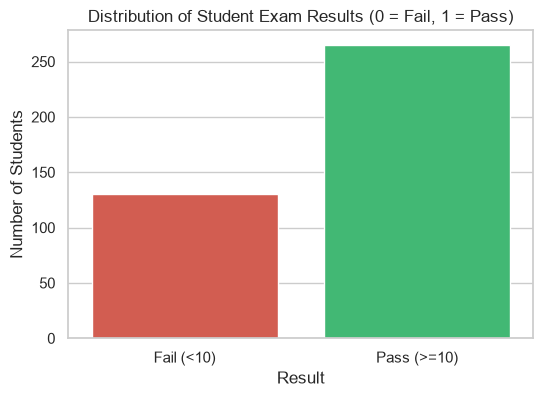

In [4]:
# Define binary target: 1 = Pass, 0 = Fail
df['Passed'] = (df['G3'] >= 10).astype(int)

# Check class distribution
pass_counts = df['Passed'].value_counts()
print("Pass/Fail Distribution:")
print(f"Passed (1): {pass_counts[1]} students ({pass_counts[1] / len(df) * 100:.1f}%)")
print(f"Failed (0): {pass_counts[0]} students ({pass_counts[0] / len(df) * 100:.1f}%)")

# Visualize target distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='Passed', data=df, hue='Passed', palette=['#e74c3c', '#2ecc71'], legend=False)
plt.title("Distribution of Student Exam Results (0 = Fail, 1 = Pass)")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.xticks([0, 1], ["Fail (<10)", "Pass (>=10)"])
plt.show()


### Preparing Features ($X$) and Target ($y$)
Machine learning algorithms only understand numbers.
1. We separate the features ($X$) from our target ($y$).
2. We drop `G3` so the model doesn't cheat by looking at the final grade directly.
3. We convert categorical text columns (like `school`, `sex`, `address`, `Mjob`, etc.) into numerical indicators using **One-Hot Encoding** (`pd.get_dummies`).


In [5]:
# Separate features (X) and target (y)
X = df.drop(columns=['G3', 'Passed'])
y = df['Passed']

# Convert categorical columns to numeric dummy variables
X = pd.get_dummies(X, drop_first=True)

print(f"Features shape after one-hot encoding: {X.shape}")
print(f"Target shape: {y.shape}")


Features shape after one-hot encoding: (395, 41)
Target shape: (395,)


### Splitting into Training and Testing Sets
To evaluate how well our model generalizes to unseen real-world data, we split:
- **80% Training Data:** Used to train the models.
- **20% Testing Data:** Kept hidden during training to test how accurately the models predict.
- `random_state=42`: Ensures reproducibility (anyone running this gets the exact same split).
- `stratify=y`: Ensures both train and test sets have the same ratio of passing and failing students.


In [6]:
# 80% train, 20% test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")


Training set: 316 samples
Testing set: 79 samples


### Feature Scaling for K-Nearest Neighbors (KNN)
- **Why scale?** KNN calculates Euclidean distances between data points. If one feature (like `absences`) ranges from 0 to 75, while another (like `studytime`) ranges from 1 to 4, the feature with larger numbers will unfairly dominate distance calculations.
- **Decision Trees** do not require scaling because they split features using independent threshold rules.
- We use `StandardScaler` to normalize features to mean = 0 and variance = 1 for KNN.


In [7]:
# Standardize features for KNN
scaler = StandardScaler()

# Fit on training data only, transform both train and test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features scaled successfully for KNN!")


Features scaled successfully for KNN!


---
## Step 3: Model Building
We build two distinct beginner-friendly classification models:
1. **Decision Tree Classifier**
2. **K-Nearest Neighbors (KNN) Classifier**

---

### Model 1: Decision Tree Classifier
**How it works:**
A Decision Tree creates a flowchart-like tree structure. At each node, it picks the feature that best separates passing students from failing students using mathematical purity criteria (like Gini Impurity).

We set `max_depth=4` to keep the tree simple, interpretable, and prevent overfitting.


In [8]:
# 1. Initialize Decision Tree
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)

# 2. Train the model
dt_model.fit(X_train, y_train)

# 3. Predict on unseen test set
dt_predictions = dt_model.predict(X_test)

# 4. Calculate accuracy
dt_accuracy = accuracy_score(y_test, dt_predictions)
print(f"Decision Tree Test Accuracy: {dt_accuracy * 100:.2f}%")


Decision Tree Test Accuracy: 87.34%


### Model 2: K-Nearest Neighbors (KNN) Classifier
**How it works:**
KNN is a memory-based, intuitive algorithm:
- To predict whether a new student will pass or fail, KNN finds the **$K$ most similar students** in the training dataset based on their feature values.
- It takes a "majority vote" among those $K$ neighbors.
- We choose $K = 5$.


In [9]:
# 1. Initialize KNN Classifier (K=5)
knn_model = KNeighborsClassifier(n_neighbors=5)

# 2. Train on scaled training data
knn_model.fit(X_train_scaled, y_train)

# 3. Predict on scaled test set
knn_predictions = knn_model.predict(X_test_scaled)

# 4. Calculate accuracy
knn_accuracy = accuracy_score(y_test, knn_predictions)
print(f"K-Nearest Neighbors Test Accuracy: {knn_accuracy * 100:.2f}%")


K-Nearest Neighbors Test Accuracy: 69.62%


---
## Step 4: Model Evaluation and Comparison

### 1. Accuracy Comparison
Let's compare the performance of both models on the test set.


,Model,Accuracy (%)
0,Decision Tree,87.34
1,K-Nearest Neighbors (KNN),69.62


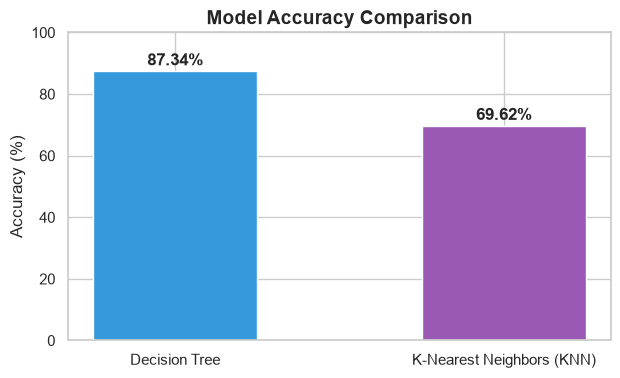

In [10]:
# Compare accuracy in a clean DataFrame
comparison_df = pd.DataFrame({
    "Model": ["Decision Tree", "K-Nearest Neighbors (KNN)"],
    "Accuracy (%)": [round(dt_accuracy * 100, 2), round(knn_accuracy * 100, 2)]
})
display(comparison_df)

# Bar plot comparison
plt.figure(figsize=(7, 4))
bars = plt.bar(comparison_df["Model"], comparison_df["Accuracy (%)"], color=['#3498db', '#9b59b6'], width=0.5)
plt.ylim(0, 100)
plt.title("Model Accuracy Comparison", fontsize=14, fontweight='bold')
plt.ylabel("Accuracy (%)")

# Add text labels on bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 2, f"{yval}%", ha='center', fontweight='bold')

plt.show()


### 2. Confusion Matrix Analysis
An accuracy score alone doesn't tell the full story. A **Confusion Matrix** shows exactly where the models made errors:
- **True Positives (TP):** Students who passed and were correctly predicted as Pass.
- **True Negatives (TN):** Students who failed and were correctly predicted as Fail.
- **False Positives (FP):** Students who failed, but the model incorrectly predicted they would Pass (Type I error).
- **False Negatives (FN):** Students who passed, but the model incorrectly predicted they would Fail (Type II error).


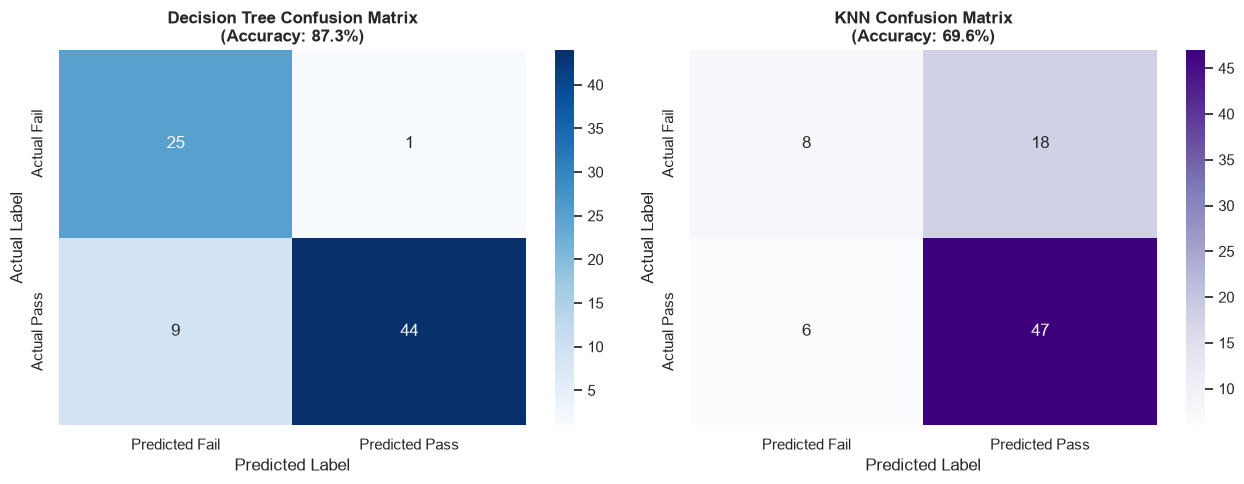

In [11]:
# Compute confusion matrices
cm_dt = confusion_matrix(y_test, dt_predictions)
cm_knn = confusion_matrix(y_test, knn_predictions)

# Plot side-by-side heatmaps
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Decision Tree Confusion Matrix
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Predicted Fail', 'Predicted Pass'],
            yticklabels=['Actual Fail', 'Actual Pass'])
axes[0].set_title(f"Decision Tree Confusion Matrix\n(Accuracy: {dt_accuracy*100:.1f}%)", fontweight='bold')
axes[0].set_ylabel("Actual Label")
axes[0].set_xlabel("Predicted Label")

# KNN Confusion Matrix
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Purples', ax=axes[1],
            xticklabels=['Predicted Fail', 'Predicted Pass'],
            yticklabels=['Actual Fail', 'Actual Pass'])
axes[1].set_title(f"KNN Confusion Matrix\n(Accuracy: {knn_accuracy*100:.1f}%)", fontweight='bold')
axes[1].set_ylabel("Actual Label")
axes[1].set_xlabel("Predicted Label")

plt.tight_layout()
plt.show()


### 3. Detailed Classification Report (Precision, Recall, F1-Score)


In [12]:
print("=== Decision Tree Classification Report ===")
print(classification_report(y_test, dt_predictions, target_names=['Fail', 'Pass']))

print("\n=== K-Nearest Neighbors Classification Report ===")
print(classification_report(y_test, knn_predictions, target_names=['Fail', 'Pass']))


=== Decision Tree Classification Report ===
              precision    recall  f1-score   support

        Fail       0.74      0.96      0.83        26
        Pass       0.98      0.83      0.90        53

    accuracy                           0.87        79
   macro avg       0.86      0.90      0.87        79
weighted avg       0.90      0.87      0.88        79


=== K-Nearest Neighbors Classification Report ===
              precision    recall  f1-score   support

        Fail       0.57      0.31      0.40        26
        Pass       0.72      0.89      0.80        53

    accuracy                           0.70        79
   macro avg       0.65      0.60      0.60        79
weighted avg       0.67      0.70      0.67        79



### 4. What factors matter most? (Decision Tree Feature Importance)
One of the greatest advantages of a Decision Tree is **interpretability**. We can inspect which student characteristics contributed most to predicting exam success.


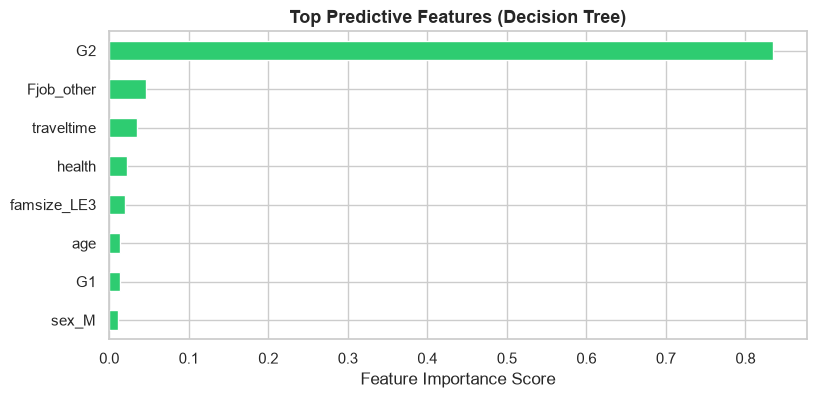

In [13]:
# Extract feature importances from the Decision Tree
importances = pd.Series(dt_model.feature_importances_, index=X.columns)
top_features = importances.sort_values(ascending=False).head(8)

plt.figure(figsize=(9, 4))
top_features.plot(kind='barh', color='#2ecc71')
plt.title("Top Predictive Features (Decision Tree)", fontsize=13, fontweight='bold')
plt.xlabel("Feature Importance Score")
plt.gca().invert_yaxis()
plt.show()


---
## Step 5: Conclusion and Learnings

### Which Model Performed Better?
- **Decision Tree** was the clear winner, achieving **87.34% accuracy** compared to **69.62% for KNN**.
- Decision Tree excelled at identifying failing students (high Recall for the Fail class: 25 out of 26 failing students correctly identified).
- KNN struggled primarily with the Fail class, misclassifying 18 failing students as passing.

### Why Did Decision Tree Outperform KNN?
1. **Curse of Dimensionality:** After one-hot encoding categorical variables, the feature space expanded to 41 dimensions. In high-dimensional space, the distance between data points becomes less informative for distance-based algorithms like KNN.
2. **Hierarchical Relationships:** Student academic progress is naturally sequential (e.g., performance in earlier periods `G2` and `G1`, combined with previous academic `failures`). Decision trees naturally model these conditional rules (e.g., *"If G2 >= 10, then likely to pass"*).

### Key Takeaways
1. **Data Preparation is 80% of Machine Learning:** Encoding categorical variables, checking missing values, and scaling features are essential prerequisites before model training.
2. **Feature Scaling is Model-Dependent:** Tree models do not require scaling, whereas distance-based models like KNN are highly sensitive to feature magnitudes.
3. **Accuracy is Not Enough:** The confusion matrix revealed that while KNN had an acceptable 70% accuracy, it missed most of the failing students. For an early warning system, identifying at-risk students (Recall) is the most critical metric.
